# Workshop 4-2: Principal Component Analysis

**Real-life problem:** Six spending columns are hard to picture and hard to explain. Can two or three numbers tell the same story?

**My twist:** Run PCA on the same wholesale data as 04-1, plot explained variance, keep enough components for about 90%, and draw a 2-D map of customers coloured by their K-means cluster.

**Done when:** A scree plot, PC1/PC2 loadings explained in words (what does PC1 mean for spending?), and a note on what the 2-D view loses.

*Baseline = the lecturer's workshop code (unmodified copy in `_baseline/`). Everything below the line starts as that baseline; edit it.*

---


## Part A: how PCA works (the lecturer's baseline, ported from the PDF)

30 measurements of breast-cancer cell nuclei (569 samples), squashed to 2 dimensions. The PDF also imports `seaborn` but never uses it, so it is left out.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
%matplotlib inline

from sklearn.datasets import load_breast_cancer
cancer = load_breast_cancer()

df = pd.DataFrame(cancer['data'], columns=cancer['feature_names'])
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [2]:
# PCA is variance-based, so put every feature on the same scale first
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(df)
scaled_data = scaler.transform(df)

In [3]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca.fit(scaled_data)
x_pca = pca.transform(scaled_data)

print(scaled_data.shape, '->', x_pca.shape)

(569, 30) -> (569, 2)


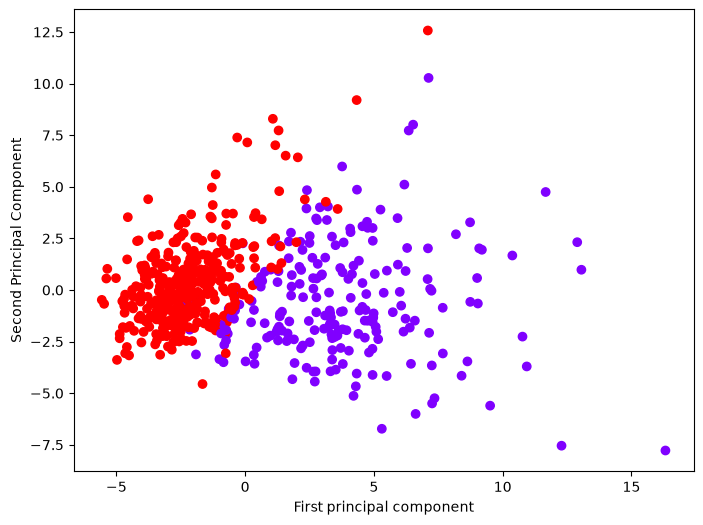

In [4]:
plt.figure(figsize=(8, 6))
plt.scatter(x_pca[:, 0], x_pca[:, 1], c=cancer['target'], cmap='rainbow')
plt.xlabel('First principal component')
plt.ylabel('Second Principal Component')
plt.show()

---
## Part B: real life: a 2-D map of wholesale customers

**Problem:** six spend columns are hard to picture and hard to explain to a non-technical colleague. Can two or three numbers tell the same story?

Same customers and the same recipe as 4-1: log-transform, standardise, K-means with k=4, segments numbered by average total spend (0 = smallest buyers).

In [5]:
from sklearn.cluster import KMeans

customers = pd.read_csv('wholesale_customers.csv')
spend_cols = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

X = StandardScaler().fit_transform(np.log1p(customers[spend_cols]))

# the 4-1 segments, rebuilt
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X)
order = customers[spend_cols].sum(axis=1).groupby(km.labels_).mean().sort_values().index
customers['segment'] = pd.Series(km.labels_).map({old: new for new, old in enumerate(order)})
customers['segment'].value_counts().sort_index()

segment
0    132
1     61
2    129
3    118
Name: count, dtype: int64

### 1. How many components do we need?
Fit PCA with all 6 components and look at how much of the total variance each one carries.

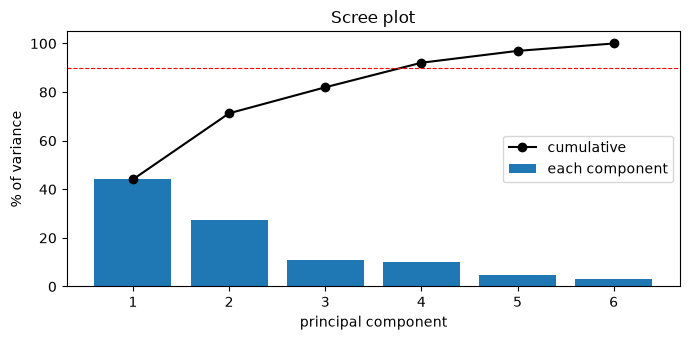

variance per component (%): [44.1, 27.2, 10.7, 10.1, 4.9, 3.0]
PC1+PC2 keep 71% of the variance; 4 components are needed for 90%


In [6]:
pca = PCA().fit(X)
evr = pca.explained_variance_ratio_
cum = evr.cumsum()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(range(1, 7), evr * 100, label='each component')
ax.plot(range(1, 7), cum * 100, 'o-', color='k', label='cumulative')
ax.axhline(90, color='r', ls='--', lw=0.8)
ax.set_xlabel('principal component'); ax.set_ylabel('% of variance')
ax.set_title('Scree plot'); ax.legend()
plt.tight_layout(); plt.show()

n90 = int(np.searchsorted(cum, 0.90) + 1)
print('variance per component (%):', (evr * 100).round(1).tolist())
print(f'PC1+PC2 keep {cum[1]*100:.0f}% of the variance; {n90} components are needed for 90%')

Two components keep about 71% of the information, and four are needed for 90%. So going from 6 columns to 4 loses little, while 2 is a good *picture* but not a lossless summary.

### 2. What do the components mean?
Each component is a weighted mix of the six spend columns. The weights are called *loadings*. (A component's sign is arbitrary, so I flip each one to make its biggest loading positive.)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
PC1,-0.11,0.54,0.57,-0.14,0.55,0.21
PC2,0.59,0.13,-0.01,0.59,-0.07,0.53
PC3,-0.64,-0.07,-0.13,-0.02,-0.20,0.73


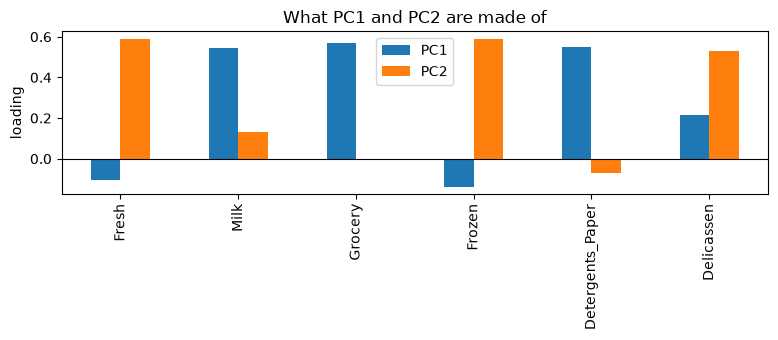

correlation of PC1 with Channel (1 = Horeca, 2 = Retail): 0.72


In [7]:
flip = np.sign(pca.components_[np.arange(6), np.abs(pca.components_).argmax(axis=1)])
loadings = pd.DataFrame(pca.components_ * flip[:, None], columns=spend_cols,
                        index=[f'PC{i}' for i in range(1, 7)])
scores = pca.transform(X) * flip                      # each customer's position on every component

display(loadings.iloc[:3].round(2))

loadings.iloc[:2].T.plot(kind='bar', figsize=(8, 3.5))
plt.axhline(0, color='k', lw=0.8); plt.ylabel('loading'); plt.title('What PC1 and PC2 are made of')
plt.tight_layout(); plt.show()

print('correlation of PC1 with Channel (1 = Horeca, 2 = Retail):', round(np.corrcoef(scores[:, 0], customers['Channel'])[0, 1], 2))

- **PC1** is high when **Milk, Grocery and Detergents_Paper** are high: the *household-goods / grocery-basket* axis. It correlates about 0.7 with `Channel`, so it is largely a Retail-vs-Horeca axis.
- **PC2** is high when **Fresh, Frozen and Delicatessen** are high: the *fresh / food-service* axis.

So six columns collapse into two readable ideas: *how much grocery-basket do they buy?* and *how much fresh food do they buy?*

### 3. The 2-D map
Every customer is one dot, coloured by its 4-1 segment.

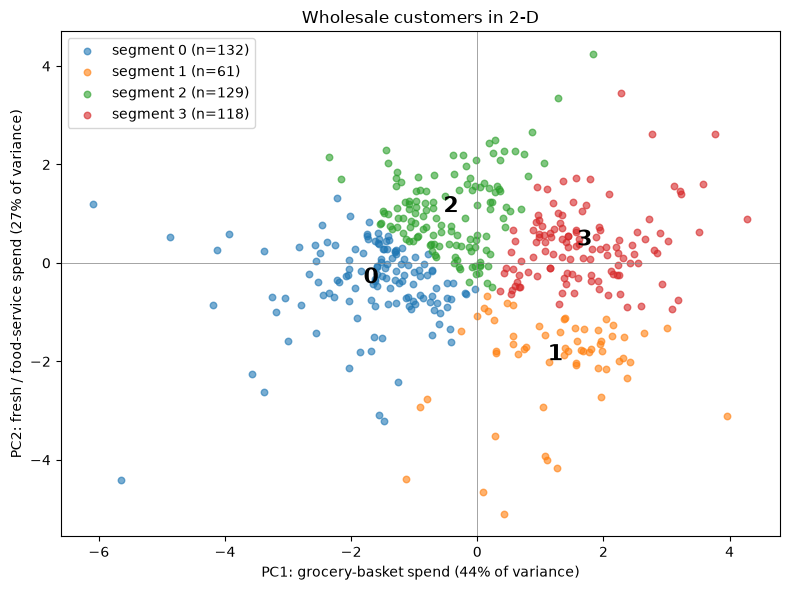

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
colors = plt.cm.tab10.colors
for s in range(4):
    m = customers['segment'] == s
    ax.scatter(scores[m, 0], scores[m, 1], s=22, alpha=0.6, color=colors[s], label=f'segment {s} (n={m.sum()})')
    ax.annotate(str(s), scores[m, :2].mean(axis=0), fontsize=16, weight='bold', ha='center')
ax.axhline(0, color='grey', lw=0.5); ax.axvline(0, color='grey', lw=0.5)
ax.set_xlabel(f'PC1: grocery-basket spend ({evr[0]*100:.0f}% of variance)')
ax.set_ylabel(f'PC2: fresh / food-service spend ({evr[1]*100:.0f}% of variance)')
ax.set_title('Wholesale customers in 2-D'); ax.legend()
plt.tight_layout(); plt.show()

### 4. What does the 2-D picture lose?

In [9]:
# if we only had the 2-D map, how often would 'nearest segment centre' give the right segment?
Z = scores[:, :2]
centres = np.array([Z[customers['segment'] == s].mean(axis=0) for s in range(4)])
nearest = np.argmin(((Z[:, None, :] - centres[None]) ** 2).sum(axis=2), axis=1)
agree = (nearest == customers['segment']).mean()

print(f'variance thrown away by dropping PC3-PC6: {(1 - cum[1]) * 100:.0f}%')
print(f'segment recovered from the 2-D map alone: {agree * 100:.0f}% of customers')
print('what PC3 is about (largest loadings):')
display(loadings.loc['PC3'].round(2).sort_values(key=abs, ascending=False).head(3))

variance thrown away by dropping PC3-PC6: 29%
segment recovered from the 2-D map alone: 98% of customers
what PC3 is about (largest loadings):


Delicassen          0.73
Fresh              -0.64
Detergents_Paper   -0.20
Name: PC3, dtype: float64

- **What survives:** the 4 segments are still almost perfectly recoverable from 2 numbers (about 98% of customers). Segment 0 is far left (small buyers), segment 3 far right (big grocery-basket buyers), segment 2 is high on the fresh axis, and segment 1 sits low on it. (Of course: the segments were found in the same data, so they follow its main directions.)
- **What is lost:** 29% of the variance. PC3 is mostly a *Fresh vs Delicatessen* contrast, so two customers can look identical on the map yet differ on that.

**Takeaway for a non-technical reader:** *"Our 440 customers differ mostly in two ways: how much everyday grocery they buy (milk, groceries, cleaning products) and how much fresh food they buy (fresh, frozen, deli). Put those two on a map and our four customer groups fall into separate areas, so a salesperson can place a customer from two questions instead of six spend figures. The map keeps about 70% of what makes customers different; the rest, such as fresh versus deli, is hidden. Use it to explain and prioritise, and go back to the full spend data when a decision needs precision."*

**What I'd check next:** would you get the same two axes if you didn't log-transform? (Hint: 4-1 showed that raw spend is dominated by a few outliers.)